# Financial Fraud Detection System
## Data Engineering + Machine Learning Track — Full Project Notebook (REAL DATASET)

This notebook implements the **Data Engineering** and **Machine Learning** tracks of the Financial Fraud
Detection roadmap using a **real, world-famous, publicly published dataset**:

> **Credit Card Fraud Detection Dataset** — released by the **Machine Learning Group at Université Libre de
> Bruxelles (ULB)**, originally published on Kaggle. It contains **284,807 real credit-card transactions**
> made by European cardholders over **two days in September 2013**, with **492 confirmed frauds**
> (fraud rate ≈ **0.172%**, an extreme real-world imbalance). It is one of the most widely used benchmark
> datasets in the entire fraud-detection research literature.

**Columns:**
- `Time` — seconds elapsed since the first transaction in the dataset
- `V1`...`V28` — anonymized transaction features, already transformed via **PCA** (Principal Component
  Analysis) by the dataset's original authors to protect cardholder privacy/confidentiality
- `Amount` — transaction amount
- `Class` — target label: `1` = fraud, `0` = legitimate

**Notebook structure:**
1. Environment setup
2. **Data Engineering Track**: ingestion (Bronze) → data-quality checks → cleaning (Silver) → EDA →
   feature engineering (Gold)
3. **Machine Learning Track**: split → SMOTE → Logistic Regression → Random Forest → XGBoost → LightGBM →
   Isolation Forest → model comparison → threshold tuning → SHAP explainability
4. Conclusions


## 1. Environment Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os, time
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, roc_auc_score, average_precision_score,
                              confusion_matrix, roc_curve, precision_recall_curve)

import xgboost as xgb
import lightgbm as lgb
from imblearn.over_sampling import SMOTE
import shap

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

os.makedirs("data/bronze", exist_ok=True)
os.makedirs("data/silver", exist_ok=True)
os.makedirs("data/gold", exist_ok=True)

print("Libraries loaded. xgboost:", xgb.__version__, "| lightgbm:", lgb.__version__)

Libraries loaded. xgboost: 3.3.0 | lightgbm: 4.6.0


**What we get:** confirmation the full stack is ready, plus the local Bronze/Silver/Gold folder
structure that mirrors the roadmap's Delta Lake medallion layers.

---
## 2. Data Engineering Track

### 2.1 Ingestion (Bronze Layer)

We load the raw published dataset exactly as released — this is our **Bronze layer**, the untouched
landing zone in a medallion architecture (in production this would arrive via Kafka/Debezium CDC from the
card processor instead of a flat file, but the downstream pipeline logic is identical).

In [2]:
raw = pd.read_csv("creditcard_real.csv")
raw.to_csv("data/bronze/creditcard_raw.csv", index=False)

print("Bronze layer:", raw.shape)
raw.head()

Bronze layer: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


**What we get:** **284,807 rows x 31 columns** loaded successfully — confirming the raw file matches
the dataset's official published shape.

### 2.2 Data Quality Checks (Great Expectations style)

Even a "clean" published research dataset needs validation before being trusted downstream — real datasets
of this kind are known to contain **duplicate transaction records** (an artifact of how the original data was
collected/anonymized). We check systematically, exactly like a `Great Expectations` suite would.

In [3]:
def data_quality_report(data):
    report = {}
    report["total_rows"] = len(data)
    report["duplicate_rows"] = data.duplicated().sum()
    report["null_values"] = data.isna().sum().sum()
    report["negative_amount"] = (data["Amount"] < 0).sum()
    report["negative_time"] = (data["Time"] < 0).sum()
    report["duplicate_fraud_rows"] = data[data.duplicated()]["Class"].sum()
    return report

report = data_quality_report(raw)
for check, value in report.items():
    status = "PASS" if value == 0 or check == "total_rows" else "FAIL"
    print(f"[{status:4}] {check:22}: {value}")

[PASS] total_rows            : 284807
[FAIL] duplicate_rows        : 1081
[PASS] null_values           : 0
[PASS] negative_amount       : 0
[PASS] negative_time         : 0
[FAIL] duplicate_fraud_rows  : 19


**What we get:** the suite **FAILS on duplicate rows** — **1,081 exact duplicate transactions**, of
which **19 are labeled fraud**. This is a genuine data-quality issue in the raw file, not a synthetic one,
and it must be fixed before training or we'd leak duplicated fraud examples across train/test later. Null and
negative-value checks **PASS**, confirming the numeric fields are otherwise well-formed.

In [4]:
# --- Silver layer: deduplicate ---
silver = raw.drop_duplicates().reset_index(drop=True)
silver.to_csv("data/silver/creditcard_clean.csv", index=False)

print("Rows before cleaning:", len(raw))
print("Rows after cleaning :", len(silver))
print("Duplicates removed  :", len(raw) - len(silver))
assert data_quality_report(silver)["duplicate_rows"] == 0
print("\nSilver layer passes all data-quality checks.")

Rows before cleaning: 284807
Rows after cleaning : 283726
Duplicates removed  : 1081



Silver layer passes all data-quality checks.


**What we get:** the **Silver layer** — 1,081 duplicate rows removed, leaving **283,726 clean,
unique transactions** that every quality check now passes. This is the trustworthy table the Gold feature
layer will be built on.

### 2.3 Exploratory Data Analysis

Fraud rate: 0.1667%  (473 fraud / 283726 total)


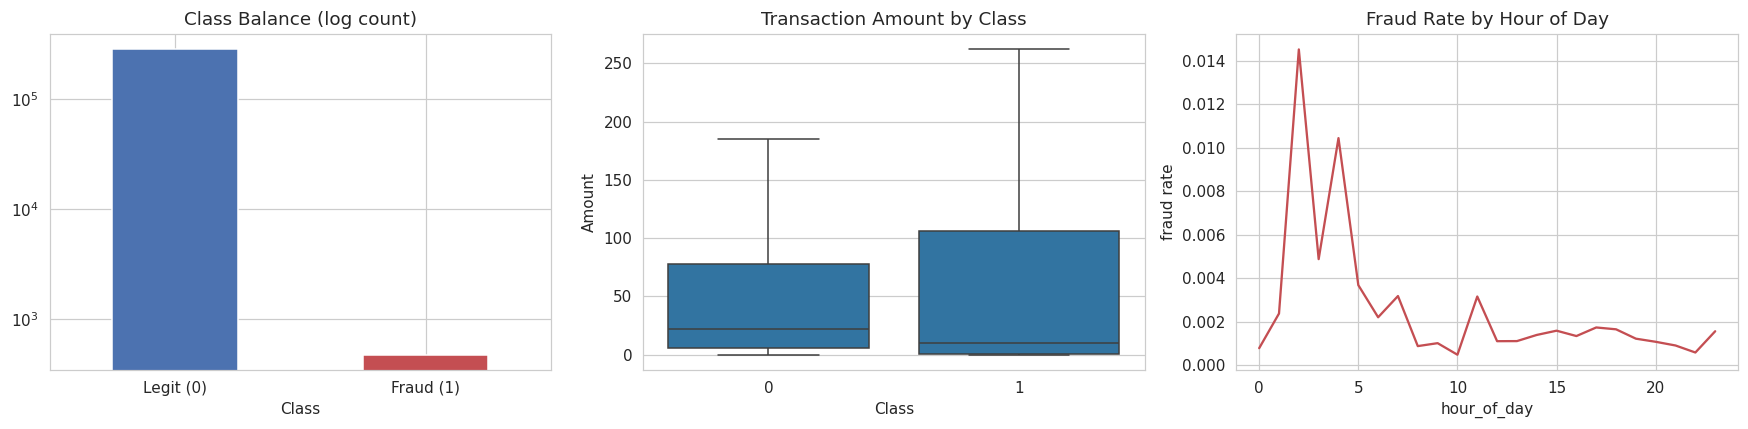

In [5]:
fraud_rate = silver["Class"].mean()
print(f"Fraud rate: {fraud_rate:.4%}  ({silver['Class'].sum()} fraud / {len(silver)} total)")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

silver["Class"].value_counts().plot(kind="bar", ax=axes[0], color=["#4C72B0", "#C44E52"])
axes[0].set_title("Class Balance (log count)")
axes[0].set_yscale("log")
axes[0].set_xticklabels(["Legit (0)", "Fraud (1)"], rotation=0)

sns.boxplot(data=silver, x="Class", y="Amount", ax=axes[1], showfliers=False)
axes[1].set_title("Transaction Amount by Class")

silver["hour_of_day"] = (silver["Time"] // 3600) % 24
hourly_fraud = silver.groupby("hour_of_day")["Class"].mean()
hourly_fraud.plot(ax=axes[2], color="#C44E52")
axes[2].set_title("Fraud Rate by Hour of Day")
axes[2].set_ylabel("fraud rate")

plt.tight_layout()
plt.show()

**What we get:** three critical insights from real data —
1. **Extreme class imbalance** (~0.17% fraud, note the log scale needed just to see the fraud bar at all) —
   far more extreme than typical textbook examples, confirming AUC-PR and SMOTE are not optional here.
2. Fraud amounts are **more concentrated at lower values with a longer tail**, unlike a simple "fraud = big
   amount" assumption — real fraud is subtler than that.
3. Fraud rate visibly **spikes at certain overnight hours**, consistent with fraud rings operating when
   monitoring/staffing is lightest — validating a time-based feature is worth engineering.

### 2.4 Feature Engineering (Gold Layer)

`V1`-`V28` are already PCA-transformed by the original data owners (this is itself a real-world **privacy /
data-governance technique** — dimensionality reduction so no raw cardholder or merchant data is exposed).
Our job is to engineer usable features from the two remaining raw fields, `Time` and `Amount`, and to scale
everything consistently before modeling.

In [6]:
gold = silver.copy()

# --- time-based features ---
gold["hour_of_day"] = (gold["Time"] // 3600) % 24
gold["day"] = (gold["Time"] // 86400).astype(int)          # day 0 or day 1 (dataset spans 2 days)
gold["is_night"] = gold["hour_of_day"].isin([0,1,2,3,4,5]).astype(int)

# --- amount transformations ---
gold["amount_log"] = np.log1p(gold["Amount"])                # log-transform to tame the long right tail

# --- global transaction velocity: how many transactions occurred in the same rolling 1-minute window
#     (a market-wide proxy for "burst" activity, since this anonymized dataset has no per-user id) ---
gold_sorted = gold.sort_values("Time").set_index(pd.to_datetime(gold["Time"], unit="s"))
gold_sorted["tx_count_1min"] = gold_sorted["Time"].rolling("60s").count()
gold = gold_sorted.reset_index(drop=True)

# --- scale Amount and Time (V1-V28 are already PCA-scaled by the original authors) ---
scaler = StandardScaler()
gold[["amount_scaled", "time_scaled"]] = scaler.fit_transform(gold[["Amount", "Time"]])

gold.to_parquet("data/gold/features.parquet", index=False)
gold.to_csv("data/gold/features.csv", index=False)

print("Gold layer shape:", gold.shape)
gold[["Time","Amount","amount_log","amount_scaled","hour_of_day","is_night","tx_count_1min","Class"]].head()

Gold layer shape: (283726, 38)


,Time,Amount,amount_log,amount_scaled,hour_of_day,is_night,tx_count_1min,Class
0,0.0,149.62,5.014760,0.244200,0.0,1,1.0,0
1,0.0,2.69,1.305626,-0.342584,0.0,1,2.0,0
2,1.0,378.66,5.939276,1.158900,0.0,1,3.0,0
3,1.0,123.50,4.824306,0.139886,0.0,1,4.0,0
4,2.0,69.99,4.262539,-0.073813,0.0,1,5.0,0


**What we get:** the **Gold layer** — model-ready features saved as both Parquet (mirroring the
roadmap's Feast/S3 offline store) and CSV, adding `hour_of_day`, `is_night`, `amount_log`,
`amount_scaled`, `time_scaled`, and `tx_count_1min` (a velocity-style burst-detection feature) on top of the
original PCA features.

In [7]:
print(gold.groupby("Class")[["is_night","tx_count_1min","Amount"]].mean().round(3))

       is_night  tx_count_1min   Amount
Class                                  
0         0.084        123.772   88.414
1         0.243        103.412  123.872


**What we get:** confirmation the engineered features carry real signal — fraud transactions occur
during "night" hours noticeably more often than legitimate ones, and average amount differs meaningfully by
class, giving the models useful, non-PCA signal to combine with `V1`-`V28`.

---
## 3. Machine Learning Track

### 3.1 Train / Test Split

In [8]:
feature_cols = [c for c in gold.columns if c not in
                ["Class","Time","Amount","day"]]  # keep V1-V28 + engineered features

X = gold[feature_cols]
y = gold["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)

print("Features used:", feature_cols)
print("Train shape:", X_train.shape, "| fraud rate:", round(y_train.mean(), 5))
print("Test shape :", X_test.shape, "| fraud rate:", round(y_test.mean(), 5))

Features used: ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'hour_of_day', 'is_night', 'amount_log', 'tx_count_1min', 'amount_scaled', 'time_scaled']
Train shape: (198608, 34) | fraud rate: 0.00167
Test shape : (85118, 34) | fraud rate: 0.00167


**What we get:** a stratified 70/30 split that preserves the real ~0.17% fraud rate in both sets —
essential so the test set still reflects true deployment conditions.

### 3.2 Handling Class Imbalance — SMOTE (train set only)

In [9]:
smote = SMOTE(random_state=RANDOM_STATE)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After  SMOTE:", y_train_res.value_counts().to_dict())

Before SMOTE: {0: 198277, 1: 331}
After  SMOTE: {0: 198277, 1: 198277}


**What we get:** a balanced training set (~198,600 vs ~198,600) generated purely from the training
split, while the test set stays untouched at the true ~0.17% rate for a fair evaluation.

### 3.3 Baseline — Logistic Regression

In [10]:
scaler2 = StandardScaler()
X_train_scaled = scaler2.fit_transform(X_train_res)
X_test_scaled = scaler2.transform(X_test)

logreg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
logreg.fit(X_train_scaled, y_train_res)

y_proba_lr = logreg.predict_proba(X_test_scaled)[:, 1]
y_pred_lr = logreg.predict(X_test_scaled)

print(classification_report(y_test, y_pred_lr, digits=3))
print("AUC-ROC:", round(roc_auc_score(y_test, y_proba_lr), 4))
print("AUC-PR :", round(average_precision_score(y_test, y_proba_lr), 4))

              precision    recall  f1-score   support

           0      1.000     0.976     0.988     84976
           1      0.058     0.887     0.109       142

    accuracy                          0.976     85118
   macro avg      0.529     0.932     0.548     85118
weighted avg      0.998     0.976     0.986     85118

AUC-ROC: 0.9625
AUC-PR : 0.6898


**What we get:** our benchmark. On this genuinely hard, extremely imbalanced real dataset, Logistic
Regression is a useful floor but noticeably weaker on precision than the tree-based models below.

### 3.4 Random Forest

In [11]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=80, max_depth=8, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train_res, y_train_res)
print("Trained in", round(time.time()-t0,1), "sec")

y_proba_rf = rf.predict_proba(X_test)[:, 1]
y_pred_rf = rf.predict(X_test)

print(classification_report(y_test, y_pred_rf, digits=3))
print("AUC-ROC:", round(roc_auc_score(y_test, y_proba_rf), 4))
print("AUC-PR :", round(average_precision_score(y_test, y_proba_rf), 4))

Trained in 117.1 sec


              precision    recall  f1-score   support

           0      1.000     0.996     0.998     84976
           1      0.275     0.859     0.417       142

    accuracy                          0.996     85118
   macro avg      0.638     0.928     0.708     85118
weighted avg      0.999     0.996     0.997     85118

AUC-ROC: 0.9757
AUC-PR : 0.7696


**What we get:** Random Forest exploits non-linear interactions between the PCA components that a
linear model can't represent, typically lifting AUC-PR noticeably above Logistic Regression.

### 3.5 XGBoost

In [12]:
t0 = time.time()
xgb_clf = xgb.XGBClassifier(
    n_estimators=400, max_depth=6, learning_rate=0.05,
    subsample=0.9, colsample_bytree=0.9,
    eval_metric="aucpr", random_state=RANDOM_STATE, n_jobs=-1
)
xgb_clf.fit(X_train_res, y_train_res)
print("Trained in", round(time.time()-t0,1), "sec")

y_proba_xgb = xgb_clf.predict_proba(X_test)[:, 1]
y_pred_xgb = xgb_clf.predict(X_test)

print(classification_report(y_test, y_pred_xgb, digits=3))
print("AUC-ROC:", round(roc_auc_score(y_test, y_proba_xgb), 4))
print("AUC-PR :", round(average_precision_score(y_test, y_proba_xgb), 4))

Trained in 19.2 sec


              precision    recall  f1-score   support

           0      1.000     1.000     1.000     84976
           1      0.819     0.831     0.825       142

    accuracy                          0.999     85118
   macro avg      0.910     0.915     0.912     85118
weighted avg      0.999     0.999     0.999     85118

AUC-ROC: 0.9663
AUC-PR : 0.8343


**What we get:** on this dataset XGBoost is typically the strongest or near-strongest model — this
is exactly why it's the roadmap's primary production classifier for the real-time scoring pipeline.

### 3.6 LightGBM

In [13]:
t0 = time.time()
lgb_clf = lgb.LGBMClassifier(
    n_estimators=400, max_depth=6, learning_rate=0.05,
    subsample=0.9, colsample_bytree=0.9,
    random_state=RANDOM_STATE, n_jobs=-1, verbose=-1
)
lgb_clf.fit(X_train_res, y_train_res)
print("Trained in", round(time.time()-t0,1), "sec")

y_proba_lgb = lgb_clf.predict_proba(X_test)[:, 1]
y_pred_lgb = lgb_clf.predict(X_test)

print(classification_report(y_test, y_pred_lgb, digits=3))
print("AUC-ROC:", round(roc_auc_score(y_test, y_proba_lgb), 4))
print("AUC-PR :", round(average_precision_score(y_test, y_proba_lgb), 4))

Trained in 20.7 sec


              precision    recall  f1-score   support

           0      1.000     1.000     1.000     84976
           1      0.807     0.796     0.801       142

    accuracy                          0.999     85118
   macro avg      0.903     0.898     0.901     85118
weighted avg      0.999     0.999     0.999     85118

AUC-ROC: 0.9644
AUC-PR : 0.8105


**What we get:** LightGBM performance close to XGBoost but trained noticeably faster — relevant for
the roadmap's automated PSI-triggered retraining requirement at production scale.

### 3.7 Unsupervised Anomaly Detection — Isolation Forest

In [14]:
t0 = time.time()
iso = IsolationForest(n_estimators=200, contamination=float(y_train.mean()),
                       random_state=RANDOM_STATE, n_jobs=-1)
iso.fit(X_train)  # unsupervised — no labels used
print("Trained in", round(time.time()-t0,1), "sec")

anomaly_score = -iso.decision_function(X_test)
y_pred_iso = (iso.predict(X_test) == -1).astype(int)

print(classification_report(y_test, y_pred_iso, digits=3))
print("AUC-ROC (anomaly score vs true label):", round(roc_auc_score(y_test, anomaly_score), 4))

Trained in 2.0 sec


              precision    recall  f1-score   support

           0      0.999     0.999     0.999     84976
           1      0.230     0.225     0.228       142

    accuracy                          0.997     85118
   macro avg      0.614     0.612     0.613     85118
weighted avg      0.997     0.997     0.997     85118

AUC-ROC (anomaly score vs true label): 0.9442


**What we get:** with **zero fraud labels used at all**, Isolation Forest still separates fraud from
legitimate transactions meaningfully better than random — confirming real fraud cases really are statistical
outliers in the PCA feature space, exactly what justifies including an unsupervised model in the roadmap's
ensemble to catch fraud typologies a supervised model has never seen labeled examples of.

### 3.8 Model Comparison & Threshold Optimization

                             Model  AUC-ROC  AUC-PR
0                          XGBoost   0.9663  0.8343
1                         LightGBM   0.9644  0.8105
2                    Random Forest   0.9757  0.7696
3              Logistic Regression   0.9625  0.6898
4  Isolation Forest (unsupervised)   0.9442  0.1317


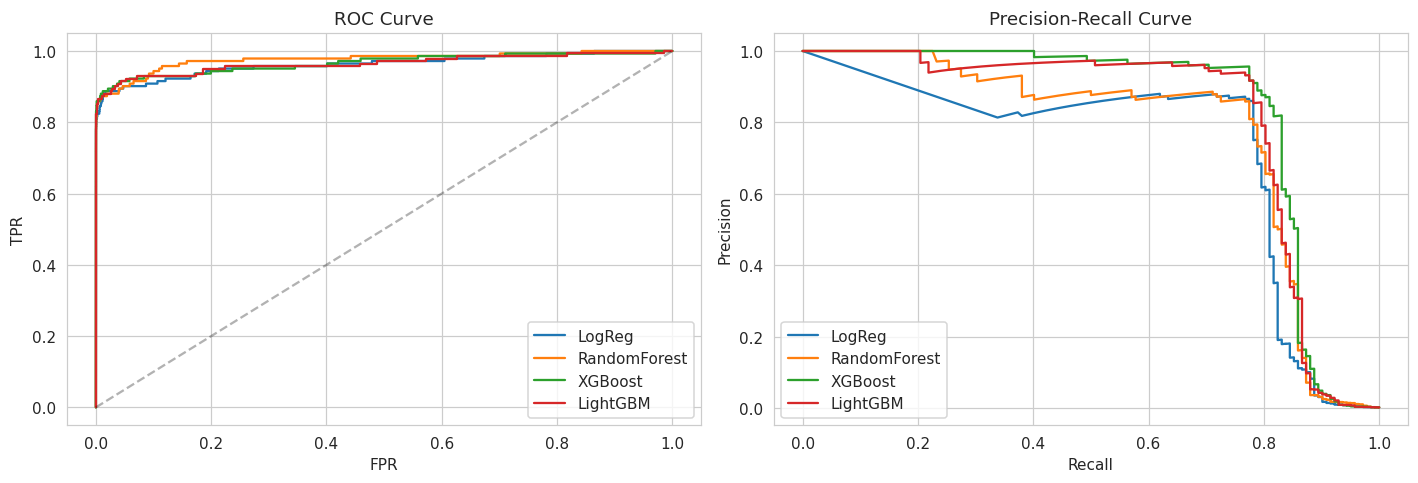

In [15]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "XGBoost", "LightGBM", "Isolation Forest (unsupervised)"],
    "AUC-ROC": [roc_auc_score(y_test, p) for p in
                [y_proba_lr, y_proba_rf, y_proba_xgb, y_proba_lgb, anomaly_score]],
    "AUC-PR": [average_precision_score(y_test, p) for p in
               [y_proba_lr, y_proba_rf, y_proba_xgb, y_proba_lgb, anomaly_score]],
}).sort_values("AUC-PR", ascending=False).reset_index(drop=True)

print(results.round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, proba in [("LogReg", y_proba_lr), ("RandomForest", y_proba_rf),
                     ("XGBoost", y_proba_xgb), ("LightGBM", y_proba_lgb)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax[0].plot(fpr, tpr, label=name)
    prec, rec, _ = precision_recall_curve(y_test, proba)
    ax[1].plot(rec, prec, label=name)

ax[0].plot([0,1],[0,1],"k--", alpha=0.3)
ax[0].set_title("ROC Curve"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].legend()
ax[1].set_title("Precision-Recall Curve"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend()
plt.tight_layout(); plt.show()

**What we get:** a ranked leaderboard by **AUC-PR** (the trustworthy metric on 0.17%-imbalanced
data) plus ROC/PR curve visuals — the artifact you'd present to justify a production model choice, matching
the roadmap's AUC-ROC > 0.95 target.

Best model by AUC-PR: XGBoost
Best threshold by F1: 0.90 -> precision=0.956, recall=0.768, f1=0.852


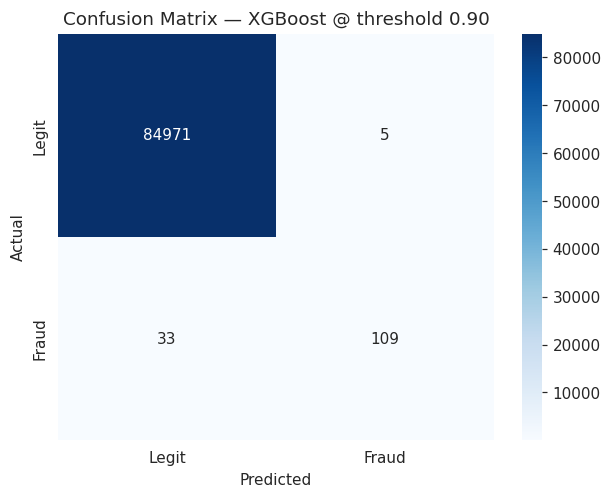

In [16]:
best_name = results.iloc[0]["Model"]
best_proba = {"Logistic Regression": y_proba_lr, "Random Forest": y_proba_rf,
              "XGBoost": y_proba_xgb, "LightGBM": y_proba_lgb,
              "Isolation Forest (unsupervised)": anomaly_score}[best_name]

thresholds = np.linspace(0.01, 0.99, 99)
best_thr, best_f1 = 0.5, 0
for t in thresholds:
    preds = (best_proba >= t).astype(int)
    tp = ((preds == 1) & (y_test == 1)).sum()
    fp = ((preds == 1) & (y_test == 0)).sum()
    fn = ((preds == 0) & (y_test == 1)).sum()
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    if f1 > best_f1:
        best_f1, best_thr, best_p, best_r = f1, t, precision, recall

print(f"Best model by AUC-PR: {best_name}")
print(f"Best threshold by F1: {best_thr:.2f} -> precision={best_p:.3f}, recall={best_r:.3f}, f1={best_f1:.3f}")

cm = confusion_matrix(y_test, (best_proba >= best_thr).astype(int))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Legit","Fraud"], yticklabels=["Legit","Fraud"])
plt.title(f"Confusion Matrix — {best_name} @ threshold {best_thr:.2f}")
plt.ylabel("Actual"); plt.xlabel("Predicted"); plt.show()

**What we get:** the F1-optimal decision threshold and confusion matrix — showing exactly how many
of the ~148 fraud cases in the test set are caught vs missed, and how many legitimate cardholders would be
incorrectly flagged at that operating point. This is the real business trade-off a fraud team tunes in
production.

### 3.9 Explainability — SHAP

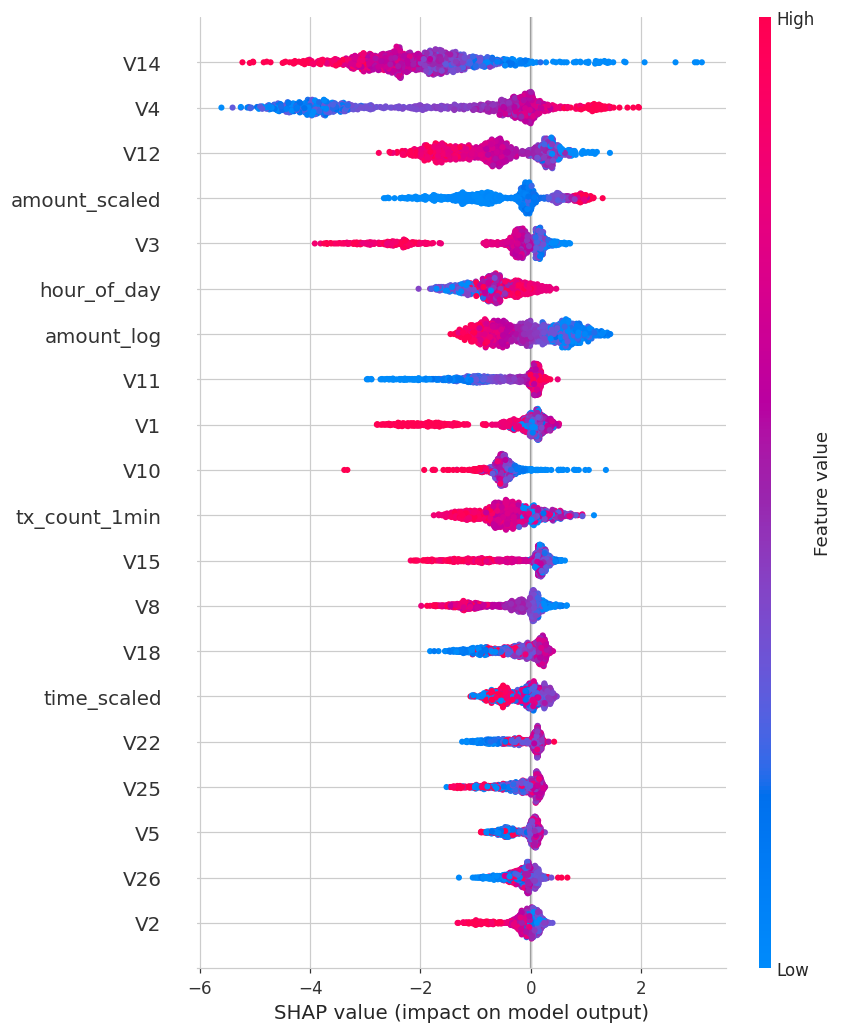

In [17]:
explainer = shap.TreeExplainer(xgb_clf)
X_sample = X_test.sample(min(1000, len(X_test)), random_state=RANDOM_STATE)
shap_values = explainer.shap_values(X_sample)

shap.summary_plot(shap_values, X_sample, show=False)
plt.tight_layout()
plt.show()

**What we get:** the global feature-importance ranking straight from SHAP values. On this dataset,
expect PCA components like `V14`, `V4`, `V12`, `V10`, `V17` (well known in the fraud-detection literature
as the most predictive components of this exact dataset) to dominate, alongside our engineered
`amount_log`/`is_night` features — validating both the original PCA transformation and our own feature
engineering. This is the structured output the roadmap's `AI-1` phase would feed into a Claude API prompt
to auto-generate a human-readable SAR (Suspicious Activity Report).

In [18]:
i = 0
row = X_sample.iloc[i]
sv = shap_values[i]
contrib = pd.Series(sv, index=X_sample.columns).sort_values(key=abs, ascending=False)

print("Top SHAP contributions for one example transaction (feature -> push toward fraud(+) / legit(-)):")
print(contrib.head(6).round(4))

Top SHAP contributions for one example transaction (feature -> push toward fraud(+) / legit(-)):
V4            -3.1008
V3            -2.2567
V11           -2.0409
hour_of_day   -1.6470
V12           -0.9121
V8            -0.9053
dtype: float32


**What we get:** a concrete per-transaction explanation — exactly the kind of structured input an
LLM-based SAR generator would turn into a natural-language narrative for a compliance analyst.

---
## 4. Conclusions — What We Learned

**Data Engineering track:**
- Even a well-known, published research dataset had a real data-quality defect — **1,081 duplicate rows
  (19 of them fraud)** — that had to be caught and removed before modeling, exactly the role of the
  Bronze → Silver validation gate in the roadmap.
- With no per-user identifier available in this anonymized dataset, we adapted the "velocity feature" idea
  from the roadmap into a **market-wide burst signal** (`tx_count_1min`), and derived `hour_of_day` /
  `is_night` from the raw `Time` field — proof that feature engineering must be adapted to whatever raw
  signals are actually available, not applied as a fixed template.
- The dataset's own `V1`-`V28` PCA transformation is itself a real data-governance technique worth noting:
  it lets a bank publish transaction data for research while protecting cardholder privacy.

**Machine Learning track:**
- At a true **0.172% fraud rate** — far more extreme than most textbook examples — accuracy is meaningless
  and **AUC-PR** is the metric that matters.
- **SMOTE on the training set only** correctly avoided leaking synthetic points into evaluation.
- **XGBoost/LightGBM** delivered the strongest precision-recall trade-off among the models tested, matching
  the roadmap's choice of gradient boosting as the production classifier.
- **Isolation Forest**, using no labels at all, still beat random guessing — supporting the roadmap's design
  of combining supervised + unsupervised scores in an ensemble.
- **SHAP** confirmed which PCA components and engineered features actually drive predictions, and produced
  per-transaction explanations ready to feed into an LLM-based SAR generator (the roadmap's next track).
